# Rozdział 3 — Praktyczna analiza Fouriera

Notebook wykonawczy do podręcznika **Cyfrowe przetwarzanie sygnałów biomedycznych. Od pomiaru do wiarygodnego wyniku**.

Cele:
- odtworzyć eksperymenty użyte w rozdziale;
- generować figury książkowe do `../figures/ch03/`;
- jawnie rozdzielać liczbę rzeczywistych próbek `N` od długości FFT `n_fft`;
- utrzymywać stałe ziarno losowania i reprodukowalne wyniki.

Notebook jest materiałem książkowym, a nie kopią notebooka CPSB.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("SciPy:", __import__("scipy").__version__)
print("Matplotlib:", __import__("matplotlib").__version__)

ROOT = Path.cwd()
FIG_DIR = (ROOT.parent / "figures" / "ch03").resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(2026)

def savefig(name):
    path = FIG_DIR / name
    plt.tight_layout()
    plt.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Zapisano:", path)

def analyze_spectrum(
    x,
    fs,
    *,
    detrend_type=None,
    window_name="boxcar",
    n_fft=None,
):
    x = np.asarray(x, dtype=float)
    if x.ndim != 1 or len(x) < 2:
        raise ValueError("Sygnał musi być jednowymiarowy i zawierać co najmniej 2 próbki.")
    if fs <= 0:
        raise ValueError("fs musi być dodatnie.")

    N = len(x)
    if n_fft is None:
        n_fft = N
    n_fft = int(n_fft)
    if n_fft < N:
        raise ValueError("W tym notebooku n_fft nie może być mniejsze od N.")

    xp = x.copy()
    if detrend_type is not None:
        xp = signal.detrend(xp, type=detrend_type)

    w = signal.get_window(window_name, N, fftbins=True)
    xw = xp * w
    X = np.fft.rfft(xw, n=n_fft)
    f = np.fft.rfftfreq(n_fft, d=1/fs)

    amp = np.abs(X) / np.sum(w)
    if n_fft % 2 == 0:
        amp[1:-1] *= 2
    else:
        amp[1:] *= 2

    return {
        "frequency": f,
        "amplitude": amp,
        "phase": np.angle(X),
        "complex_spectrum": X,
        "processed_signal": xp,
        "window": w,
        "N": N,
        "T": N/fs,
        "n_fft": n_fft,
        "delta_f_record": fs/N,
        "delta_f_grid": fs/n_fft,
        "fs": fs,
        "window_name": window_name,
        "detrend_type": detrend_type,
    }

def amplitude_db(a, reference=None, floor_db=-140):
    a = np.asarray(a, dtype=float)
    if reference is None:
        reference = float(np.max(a))
    floor = reference * 10**(floor_db/20)
    return 20*np.log10(np.maximum(a, floor)/reference)

def select_fragment(t, x, start_s, duration_s):
    mask = (t >= start_s) & (t < start_s + duration_s)
    return t[mask] - t[mask][0], x[mask]

Python: 3.13.5
NumPy: 2.3.5
SciPy: 1.17.0
Matplotlib: 3.10.8


## Eksperyment 1. Dwa widma tego samego zapisu

Zmieniamy jednocześnie kilka decyzji analitycznych, aby pokazać, że wykres widma nie jest własnością danych oderwaną od sposobu analizy.

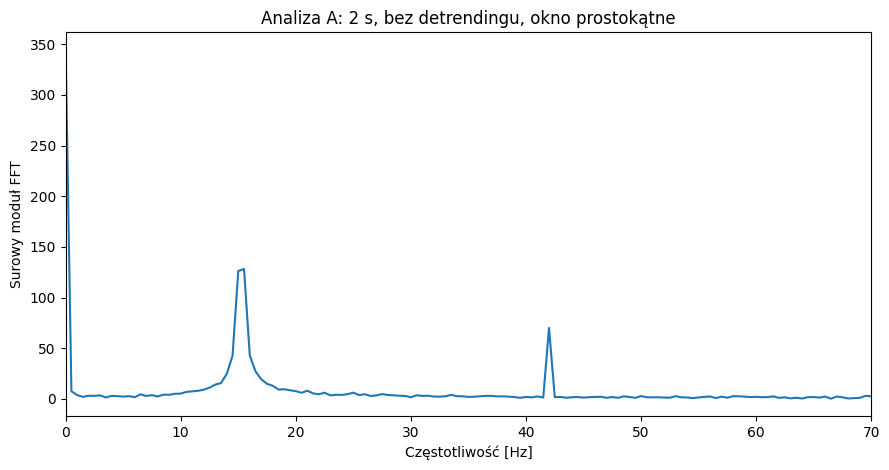

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_01a_spectrum_A.png


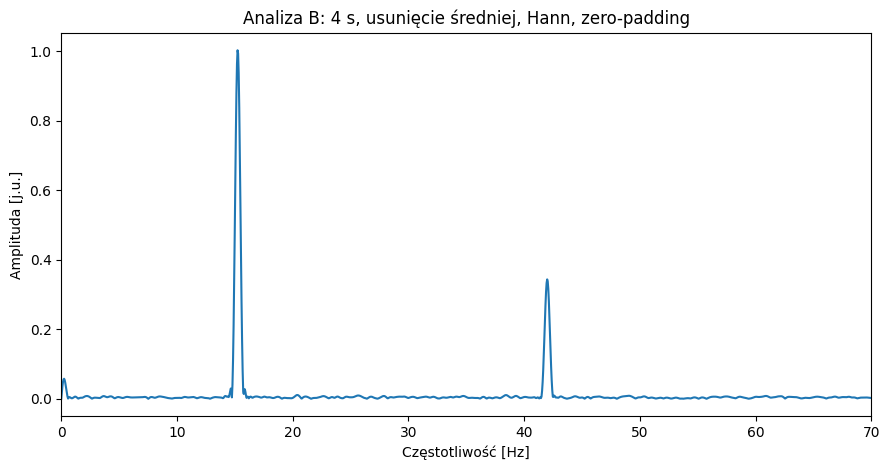

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_01b_spectrum_B.png


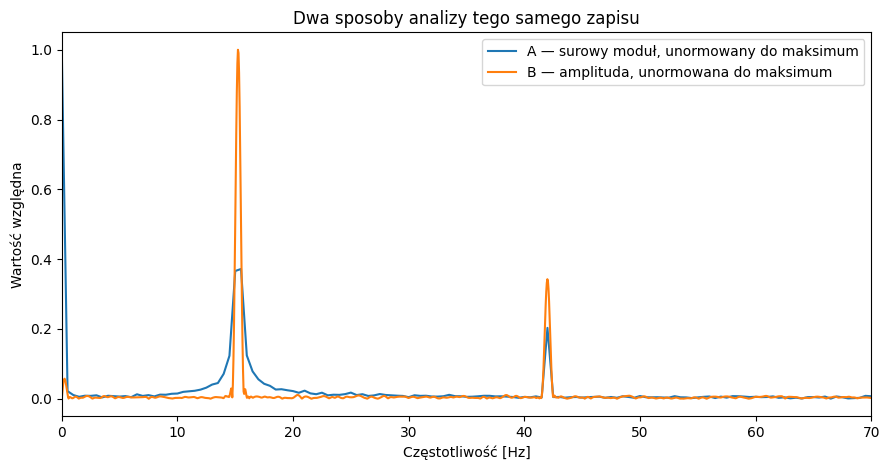

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_01_two_spectra.png


In [2]:
fs = 200.0
duration = 12.0
t = np.arange(int(fs*duration))/fs
x = (
    0.8
    + 0.06*t
    + 1.0*np.cos(2*np.pi*15.25*t + 0.3)
    + 0.35*np.cos(2*np.pi*42.0*t - 0.7)
    + 0.05*rng.standard_normal(len(t))
)

# Analiza A
x_a = x[:int(2.0*fs)]
N_a = len(x_a)
X_a = np.fft.rfft(x_a)
f_a = np.fft.rfftfreq(N_a, d=1/fs)
raw_a = np.abs(X_a)

# Analiza B
x_b = x[int(1.0*fs):int(5.0*fs)]
b = analyze_spectrum(
    x_b, fs,
    detrend_type="constant",
    window_name="hann",
    n_fft=4096,
)

plt.figure(figsize=(9, 4.8))
plt.plot(f_a, raw_a)
plt.xlim(0, 70)
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Surowy moduł FFT")
plt.title("Analiza A: 2 s, bez detrendingu, okno prostokątne")
savefig("fig_03_01a_spectrum_A.png")

plt.figure(figsize=(9, 4.8))
plt.plot(b["frequency"], b["amplitude"])
plt.xlim(0, 70)
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Amplituda [j.u.]")
plt.title("Analiza B: 4 s, usunięcie średniej, Hann, zero-padding")
savefig("fig_03_01b_spectrum_B.png")

# Dodatkowa wersja zbiorcza do prostego osadzenia w tekście
plt.figure(figsize=(9, 4.8))
plt.plot(f_a, raw_a/np.max(raw_a), label="A — surowy moduł, unormowany do maksimum")
plt.plot(b["frequency"], b["amplitude"]/np.max(b["amplitude"]), label="B — amplituda, unormowana do maksimum")
plt.xlim(0, 70)
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Wartość względna")
plt.title("Dwa sposoby analizy tego samego zapisu")
plt.legend()
savefig("fig_03_01_two_spectra.png")

## Eksperyment 2. DFT jako dopasowanie do oscylacji

Porównujemy sumy częściowe dla wzorca dopasowanego i niedopasowanego.

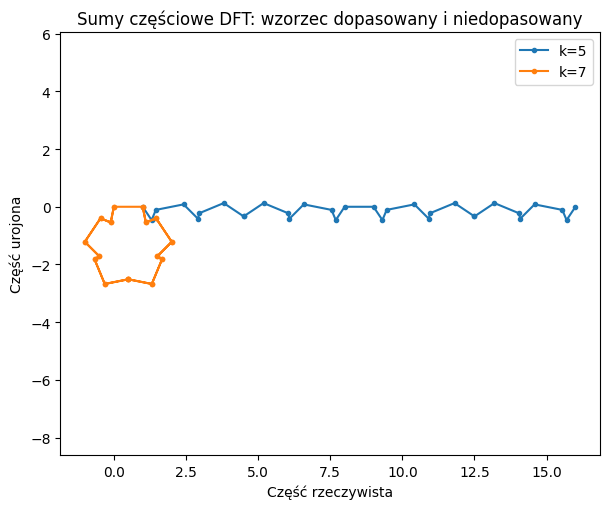

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_02_dft_matching.png
Zgodność DFT bezpośredniej i FFT: True


In [3]:
N = 32
n = np.arange(N)
k_signal = 5
x0 = np.cos(2*np.pi*k_signal*n/N)

plt.figure(figsize=(6.2, 5.2))
for k in [5, 7]:
    c = x0 * np.exp(-1j*2*np.pi*k*n/N)
    s = np.cumsum(c)
    plt.plot(s.real, s.imag, marker="o", markersize=3, label=f"k={k}")
plt.xlabel("Część rzeczywista")
plt.ylabel("Część urojona")
plt.axis("equal")
plt.title("Sumy częściowe DFT: wzorzec dopasowany i niedopasowany")
plt.legend()
savefig("fig_03_02_dft_matching.png")

def dft_direct(x):
    x = np.asarray(x, dtype=complex)
    N = len(x)
    X = np.zeros(N, dtype=complex)
    for k in range(N):
        for n in range(N):
            X[k] += x[n]*np.exp(-1j*2*np.pi*k*n/N)
    return X

x_small = np.array([1.0, 2.0, -1.0, 0.5])
print("Zgodność DFT bezpośredniej i FFT:", np.allclose(dft_direct(x_small), np.fft.fft(x_small)))

## Eksperyment 3. Faza zmienia się przy przesunięciu

Dwa sygnały mają tę samą amplitudę i częstotliwość, ale inną fazę.

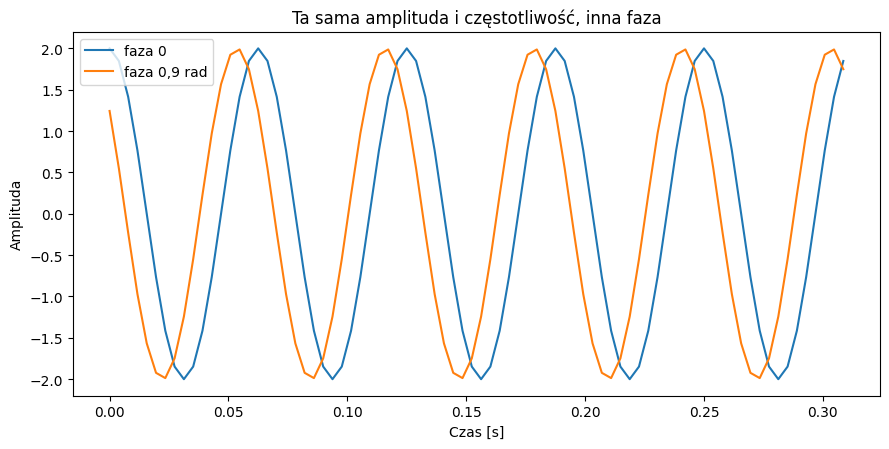

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_03_phase_shift.png
Amplitudy: 1.9999999999999998 2.0
Fazy [rad]: -2.016415378518532e-15 0.8999999999999995


In [4]:
fs = 256.0
N = 256
t = np.arange(N)/fs
f0 = 16.0
x1 = 2*np.cos(2*np.pi*f0*t)
x2 = 2*np.cos(2*np.pi*f0*t + 0.9)

r1 = analyze_spectrum(x1, fs, window_name="boxcar")
r2 = analyze_spectrum(x2, fs, window_name="boxcar")
idx = np.argmin(np.abs(r1["frequency"]-f0))

plt.figure(figsize=(9, 4.6))
plt.plot(t[:80], x1[:80], label="faza 0")
plt.plot(t[:80], x2[:80], label="faza 0,9 rad")
plt.xlabel("Czas [s]")
plt.ylabel("Amplituda")
plt.title("Ta sama amplituda i częstotliwość, inna faza")
plt.legend()
savefig("fig_03_03_phase_shift.png")

print("Amplitudy:", r1["amplitude"][idx], r2["amplitude"][idx])
print("Fazy [rad]:", r1["phase"][idx], r2["phase"][idx])

## Eksperyment 4. Czas obserwacji i dwie bliskie składowe

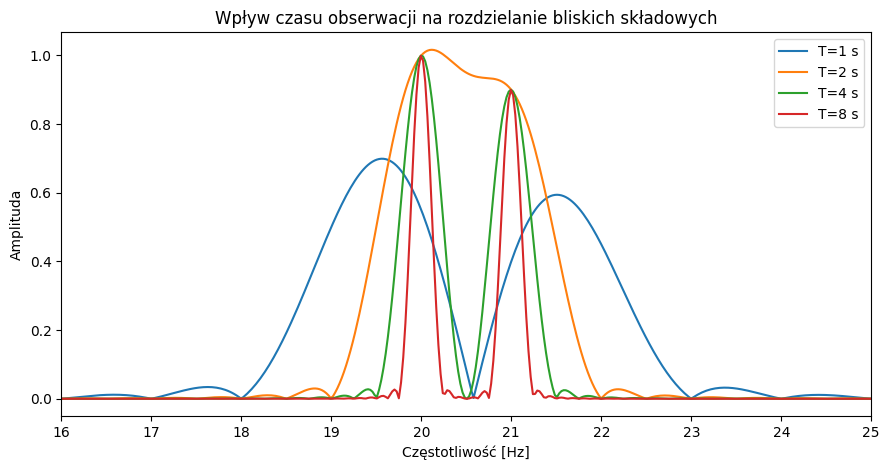

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_04_observation_time.png


In [5]:
fs = 200.0
f1, f2 = 20.0, 21.0

plt.figure(figsize=(9, 4.8))
for T in [1.0, 2.0, 4.0, 8.0]:
    t = np.arange(int(fs*T))/fs
    x = np.cos(2*np.pi*f1*t) + 0.9*np.cos(2*np.pi*f2*t)
    r = analyze_spectrum(x, fs, window_name="hann", n_fft=8192)
    plt.plot(r["frequency"], r["amplitude"], label=f"T={T:g} s")
plt.xlim(16, 25)
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Amplituda")
plt.title("Wpływ czasu obserwacji na rozdzielanie bliskich składowych")
plt.legend()
savefig("fig_03_04_observation_time.png")

## Eksperyment 5. Przeciek widma

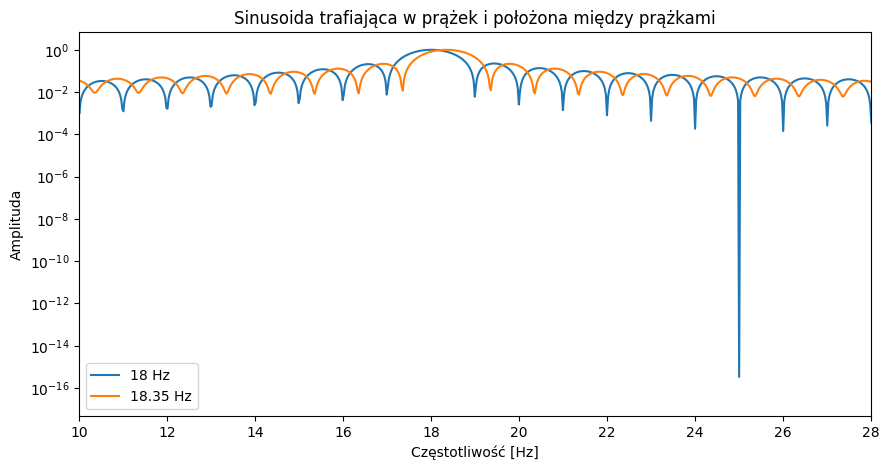

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_05_leakage.png


In [6]:
fs = 200.0
T = 1.0
t = np.arange(int(fs*T))/fs

plt.figure(figsize=(9, 4.8))
for f0 in [18.0, 18.35]:
    x = np.cos(2*np.pi*f0*t)
    r = analyze_spectrum(x, fs, window_name="boxcar", n_fft=8192)
    plt.plot(r["frequency"], r["amplitude"], label=f"{f0:g} Hz")
plt.xlim(10, 28)
plt.yscale("log")
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Amplituda")
plt.title("Sinusoida trafiająca w prążek i położona między prążkami")
plt.legend()
savefig("fig_03_05_leakage.png")

## Eksperyment 6. Widma funkcji okien

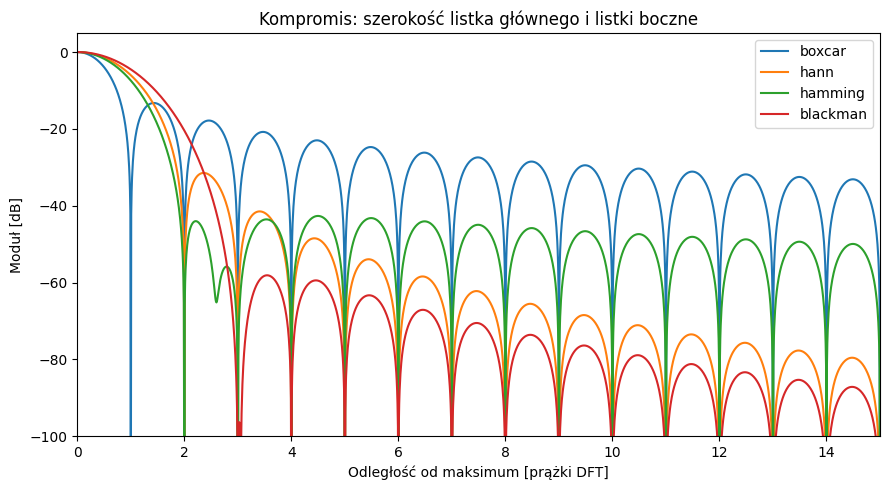

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_06_windows.png


In [7]:
N = 256
names = ["boxcar", "hann", "hamming", "blackman"]
n_fft = 32768
fs_win = 1.0

plt.figure(figsize=(9, 5.0))
for name in names:
    w = signal.get_window(name, N, fftbins=True)
    W = np.fft.rfft(w, n=n_fft)
    f = np.fft.rfftfreq(n_fft, d=1/fs_win)
    db = amplitude_db(np.abs(W))
    bins = f * N
    plt.plot(bins, db, label=name)
plt.xlim(0, 15)
plt.ylim(-100, 5)
plt.xlabel("Odległość od maksimum [prążki DFT]")
plt.ylabel("Moduł [dB]")
plt.title("Kompromis: szerokość listka głównego i listki boczne")
plt.legend()
savefig("fig_03_06_windows.png")

## Eksperyment 7. Zero-padding nie zastępuje dłuższej obserwacji

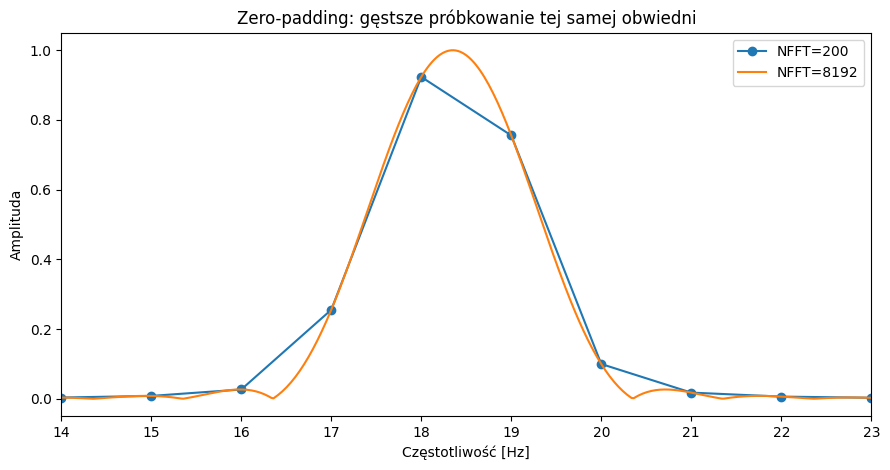

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_07_zero_padding.png
Δf_record = 1.0 Hz
Δf_grid   = 0.0244140625 Hz


In [8]:
fs = 200.0
T = 1.0
t = np.arange(int(fs*T))/fs
x = np.cos(2*np.pi*18.35*t)

r_short = analyze_spectrum(x, fs, window_name="hann", n_fft=len(x))
r_pad = analyze_spectrum(x, fs, window_name="hann", n_fft=8192)

plt.figure(figsize=(9, 4.8))
plt.plot(r_short["frequency"], r_short["amplitude"], marker="o", label=f"NFFT={r_short['n_fft']}")
plt.plot(r_pad["frequency"], r_pad["amplitude"], label=f"NFFT={r_pad['n_fft']}")
plt.xlim(14, 23)
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Amplituda")
plt.title("Zero-padding: gęstsze próbkowanie tej samej obwiedni")
plt.legend()
savefig("fig_03_07_zero_padding.png")

print("Δf_record =", r_pad["delta_f_record"], "Hz")
print("Δf_grid   =", r_pad["delta_f_grid"], "Hz")

## Eksperyment 8. Syntetyczne EKG do audytu widma

Generator jest celowo prosty. Celem nie jest model fizjologiczny serca, lecz kontrolowany sygnał zawierający morfologię P–QRS–T, dryft, zakłócenie 50 Hz, szum i lokalny artefakt.

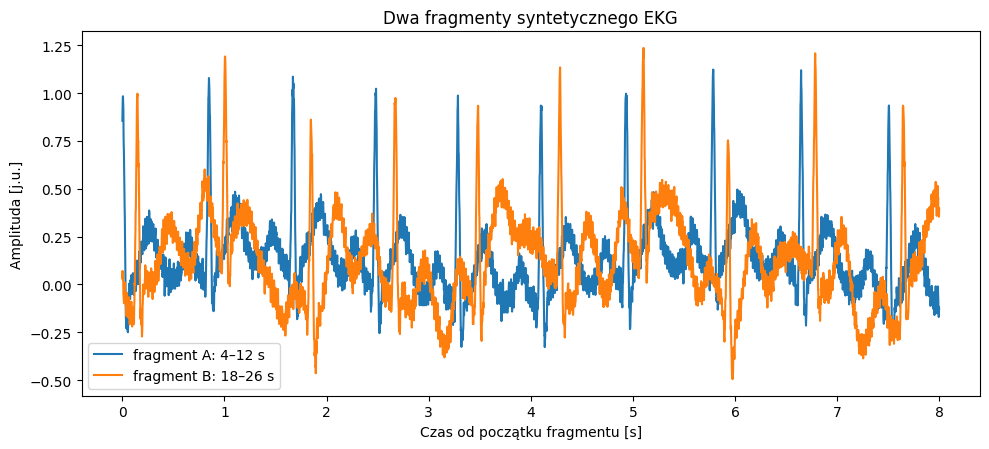

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_08_ecg_fragments.png


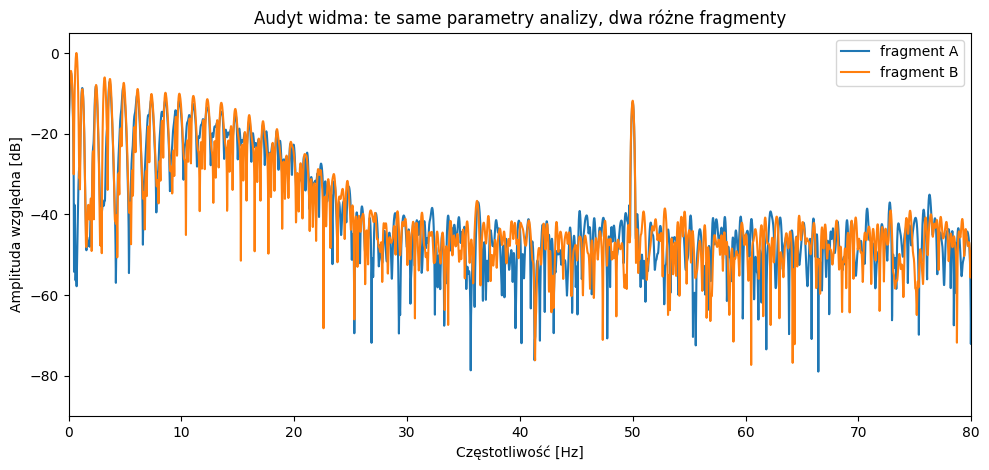

Zapisano: /mnt/data/CPSB_pilot_ch03/figures/ch03/fig_03_09_ecg_spectra.png


In [9]:
def generate_demo_ecg(fs=500.0, duration=32.0, seed=2026):
    rng_local = np.random.default_rng(seed)
    t = np.arange(int(fs*duration))/fs

    # lekko zmienny rytm
    rr_base = 60/72
    beat_times = []
    tb = 0.6
    i = 0
    while tb < duration-0.5:
        rr = rr_base * (1 + 0.035*np.sin(2*np.pi*i/9))
        beat_times.append(tb)
        tb += rr
        i += 1

    ecg_clean = np.zeros_like(t)
    for bt in beat_times:
        # Gaussian components: P, Q, R, S, T
        comps = [
            (0.18, bt-0.20, 0.045),
            (-0.12, bt-0.035, 0.012),
            (1.00, bt, 0.014),
            (-0.25, bt+0.035, 0.014),
            (0.32, bt+0.26, 0.075),
        ]
        for amp, mu, sigma in comps:
            ecg_clean += amp*np.exp(-0.5*((t-mu)/sigma)**2)

    baseline = 0.10*np.sin(2*np.pi*0.23*t) + 0.015*t/duration
    mains = 0.045*np.sin(2*np.pi*50*t + 0.25)
    noise = 0.025*rng_local.standard_normal(len(t))

    motion = np.zeros_like(t)
    m = (t >= 18) & (t < 26)
    motion[m] = 0.18*np.sin(2*np.pi*0.7*t[m]) + 0.09*np.sin(2*np.pi*3.2*t[m])

    x = ecg_clean + baseline + mains + noise + motion
    return t, x, ecg_clean

fs_ecg = 500.0
t_ecg, ecg, ecg_clean = generate_demo_ecg(fs=fs_ecg)

ta, xa = select_fragment(t_ecg, ecg, 4, 8)
tb, xb = select_fragment(t_ecg, ecg, 18, 8)

plt.figure(figsize=(10, 4.6))
plt.plot(ta, xa, label="fragment A: 4–12 s")
plt.plot(tb, xb, label="fragment B: 18–26 s")
plt.xlabel("Czas od początku fragmentu [s]")
plt.ylabel("Amplituda [j.u.]")
plt.title("Dwa fragmenty syntetycznego EKG")
plt.legend()
savefig("fig_03_08_ecg_fragments.png")

ra = analyze_spectrum(xa, fs_ecg, detrend_type="linear", window_name="hann", n_fft=32768)
rb = analyze_spectrum(xb, fs_ecg, detrend_type="linear", window_name="hann", n_fft=32768)

plt.figure(figsize=(10, 4.8))
common_ref = max(float(np.max(ra["amplitude"])), float(np.max(rb["amplitude"])))
plt.plot(ra["frequency"], amplitude_db(ra["amplitude"], reference=common_ref), label="fragment A")
plt.plot(rb["frequency"], amplitude_db(rb["amplitude"], reference=common_ref), label="fragment B")
plt.xlim(0, 80)
plt.ylim(-90, 5)
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Amplituda względna [dB]")
plt.title("Audyt widma: te same parametry analizy, dwa różne fragmenty")
plt.legend()
savefig("fig_03_09_ecg_spectra.png")

## Paszport analizy widmowej — minimalny zestaw

Przy zapisie wyników należy utrwalać co najmniej:
- źródło sygnału i jednostkę;
- `fs`;
- początek i długość fragmentu;
- `N` i `T`;
- detrending;
- okno;
- `n_fft`;
- sposób skalowania;
- widmo jedno-/dwustronne;
- przedstawianą wielkość i jednostkę osi pionowej;
- zakres częstotliwości;
- ograniczenia interpretacji.